### 2(b) Implementation of Bagging, Random Forest and Boosting

**Aim:** To implement and analyze ensemble learning techniques using Python.

**Theory:**

Ensemble learning combines multiple models to improve prediction performance.

- **Bagging:** Trains multiple models on different bootstrap samples and combines their predictions.
- **Random Forest:** Combines multiple decision trees trained using bootstrap samples and random subsets of features.
- **Boosting:** Builds models sequentially, with each new model attempting to correct errors made by previous models.

In this experiment, Gradient Boosting is used as the boosting algorithm.

**Evaluation Metrics:** Accuracy, precision, recall, and F1-score.

**Dataset:** Breast Cancer dataset available in Scikit-learn.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay


In [2]:
data = load_breast_cancer()
X, y = data.data, data.target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
models = {
    "Bagging": BaggingClassifier(n_estimators=100, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}
results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0)
    })
display(pd.DataFrame(results).round(3))

,Model,Accuracy,Precision,Recall,F1
0,Bagging,0.939,0.945,0.958,0.952
1,Random Forest,0.956,0.959,0.972,0.966
2,Gradient Boosting,0.956,0.947,0.986,0.966


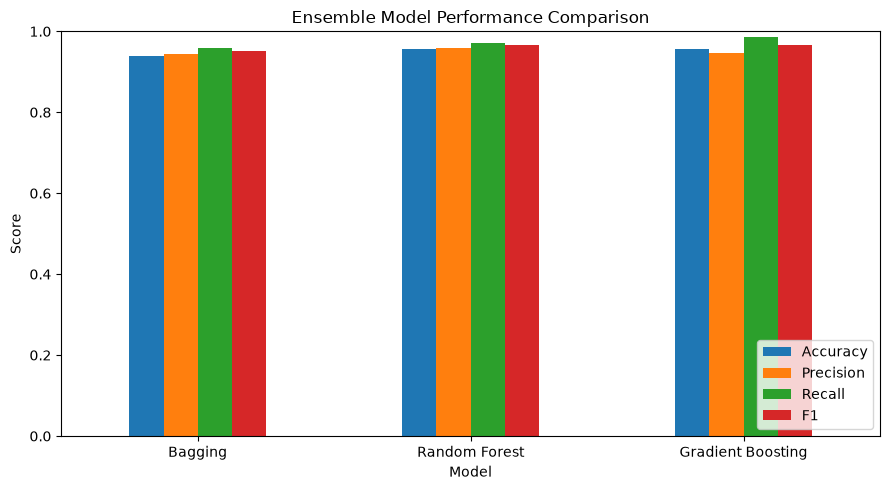

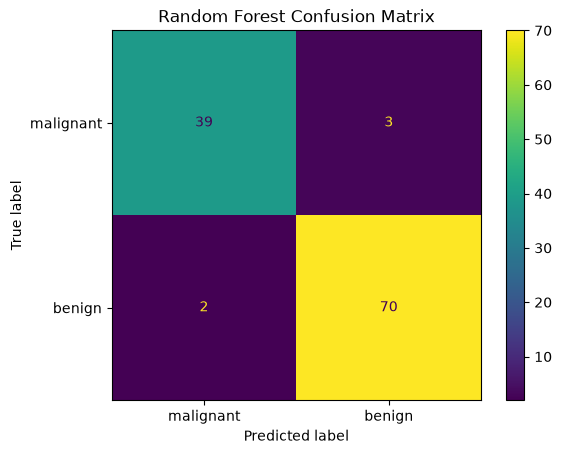

In [3]:
# Graph: compare ensemble model metrics
metrics = pd.DataFrame(results).set_index("Model")[["Accuracy", "Precision", "Recall", "F1"]]
metrics.plot(kind="bar", figsize=(9, 5), ylim=(0, 1), rot=0)
plt.title("Ensemble Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

ConfusionMatrixDisplay.from_estimator(models["Random Forest"], X_test, y_test,
                                      display_labels=data.target_names)
plt.title("Random Forest Confusion Matrix")
plt.show()

**Result and Conclusion:**

Bagging, Random Forest, and Gradient Boosting classifiers were implemented and evaluated using the breast cancer dataset.

Their performance was compared using accuracy, precision, recall, and F1-score. Graphs were plotted to compare the evaluation metrics, and a confusion matrix was generated for Random Forest.

The comparison demonstrates how different ensemble techniques can improve predictive performance.